# Systèmes Radar — Bureau d'études pratique - Atelier 1 et 2

## Notebook interactif — Formation initiation radar
*Franck Daout — IUT de Ville d'Avray (Université de Nanterre) / CFD Bourges*

---

> **Comment utiliser ce notebook ?**
> Chaque section alterne entre des cellules **Markdown** (théorie, énoncés, démarche) et des cellules **Code Python** (calculs, tracés). Exécutez les cellules dans l'ordre. Les cellules de code sont autonomes mais s'appuient sur les imports de la cellule d'initialisation.

---

*Dernière mise à jour : 16 juin 2026*

# Cellule 0 — Initialisation (imports)

In [2]:
# Imports nécessaires pour l'ensemble du notebook
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Constante physique fondamentale
c = 3e8  # vitesse de la lumière / des ondes électromagnétiques (m/s)

print("Bibliothèques chargées.")

Bibliothèques chargées.


# Partie 1 — Radar impulsionnel : principes fondamentaux

## 1.1 Principe de fonctionnement

Un radar impulsionnel émet des **impulsions électromagnétiques brèves** et écoute les **échos** renvoyés par les cibles. Quatre propriétés fondamentales découlent de ce principe :

| Phénomène ou action | Propriété du radar |
|---|---|
| Modification du signal reçu | → **Détection** |
| Mesure du temps aller-retour de l'impulsion | → **Localisation en distance** |
| Directivité de l'antenne | → **Localisation angulaire** |
| Traitement de l'effet Doppler | → **Mesure de la vitesse** |

## 1.2 Mesure de la distance

Le radar mesure le **temps aller-retour** $\Delta t$ du signal pour en déduire la distance à la cible :

$$D = \frac{c \cdot \Delta t}{2}$$

où :
- $D$ : distance à la cible (m)
- $c$ : vitesse de la lumière ($3 \times 10^8$ m/s)
- $\Delta t$ : temps de propagation aller-retour (s)

## 1.3 Résolution en distance

La **résolution en distance** $\delta_r$ est la capacité du radar à distinguer deux cibles proches comme étant distinctes. Elle dépend de la **durée de l'impulsion** $\tau$ :

$$\delta_r = \frac{c \cdot \tau}{2}$$

> Plus l'impulsion est courte, meilleure est la résolution.

## 1.4 Zone aveugle

Pendant l'émission d'une impulsion, le radar ne peut pas recevoir d'échos : il est « aveugle ». La **distance aveugle** (distance minimale détectable) est :

$$D_{\text{aveugle}} = \frac{c \cdot \tau}{2}$$

> Remarque : La formule est formellement identique à la résolution, mais la signification physique est différente — il s'agit ici de la **distance minimale détectable**.

## 1.5 Portée non ambiguë (distance maximale)

Si un écho revient **après** l'émission de l'impulsion suivante, le radar l'associe à tort à cette nouvelle impulsion : c'est l'**ambiguïté de distance**. La portée non ambiguë est :

$$R_{\max} = \frac{c \cdot (T - \tau)}{2} = \frac{c \cdot (PRT - \tau)}{2}$$

où $T = PRT = \frac{1}{PRF}$ est la période de répétition des impulsions.

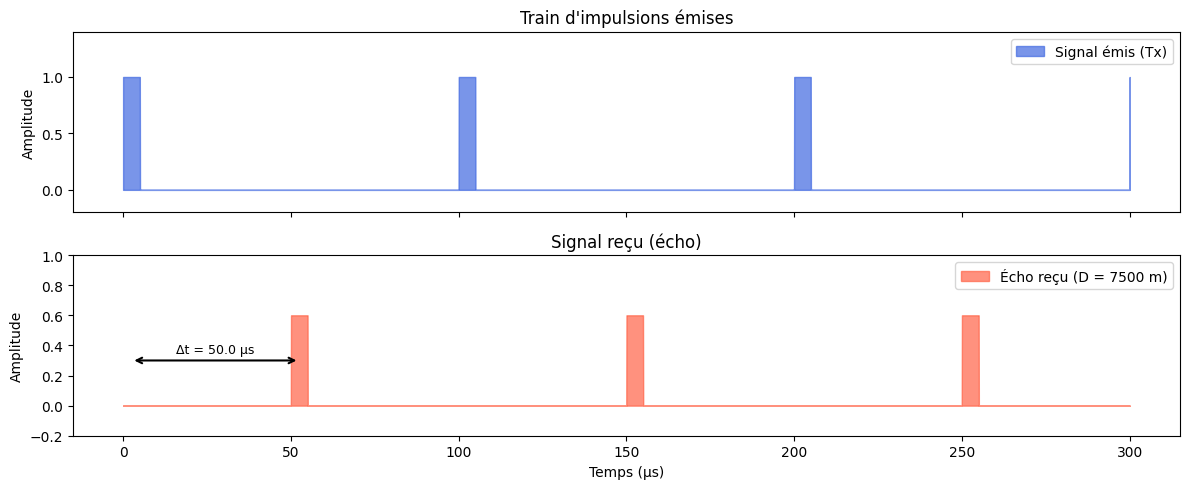


Paramètres de l'illustration :
  PRF = 10 kHz  →  PRT = 100 µs
  τ   = 5 µs
  Cible à D = 7500 m  →  Δt = 50.0 µs


In [4]:
# ── Cellule d'illustration ──────────────────────────────────────────────────
# Visualisation des paramètres temporels d'un radar impulsionnel

PRF_ex = 10e3       # Fréquence de répétition (Hz)
tau_ex  = 5e-6      # Durée d'impulsion (s)
PRT_ex  = 1 / PRF_ex

t = np.linspace(0, 3 * PRT_ex, 5000)

def pulse_train(t, tau, PRT, amplitude=1.0):
    """Génère un train d'impulsions rectangulaires."""
    signal = np.zeros_like(t)
    for k in range(10):
        t0 = k * PRT
        signal += amplitude * ((t >= t0) & (t < t0 + tau)).astype(float)
    return signal

signal_tx = pulse_train(t, tau_ex, PRT_ex, 1.0)

# Écho simulé à D = 7 500 m → Δt = 2D/c = 50 µs
D_cible = 7500
delta_t  = 2 * D_cible / c
signal_rx = pulse_train(t - delta_t, tau_ex, PRT_ex, 0.6)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

axes[0].fill_between(t * 1e6, signal_tx, alpha=0.7, color='royalblue', label='Signal émis (Tx)')
axes[0].set_ylabel("Amplitude")
axes[0].set_title("Train d'impulsions émises")
axes[0].legend(loc='upper right')
axes[0].set_ylim(-0.2, 1.4)

axes[1].fill_between(t * 1e6, signal_rx, alpha=0.7, color='tomato', label=f'Écho reçu (D = {D_cible} m)')
axes[1].set_xlabel("Temps (µs)")
axes[1].set_ylabel("Amplitude")
axes[1].set_title("Signal reçu (écho)")
axes[1].legend(loc='upper right')
axes[1].set_ylim(-0.2, 1.0)

# Annotation du délai
axes[1].annotate('', xy=(delta_t*1e6 + tau_ex*1e6/2, 0.3),
                 xytext=(tau_ex*1e6/2, 0.3),
                 arrowprops=dict(arrowstyle='<->', color='black', lw=1.5))
axes[1].text((delta_t*1e6)/2 + tau_ex*1e6/2, 0.35,
             f'Δt = {delta_t*1e6:.1f} µs', ha='center', fontsize=9)

plt.tight_layout()
#plt.savefig("radar_impulsionnel_illustration.png", dpi=120)
plt.show()
print(f"\nParamètres de l'illustration :")
print(f"  PRF = {PRF_ex/1e3:.0f} kHz  →  PRT = {PRT_ex*1e6:.0f} µs")
print(f"  τ   = {tau_ex*1e6:.0f} µs")
print(f"  Cible à D = {D_cible} m  →  Δt = {delta_t*1e6:.1f} µs")

# Atelier 1 — Étude d'un signal radar impulsionnel

## Énoncé

On dispose du signal radar ci-dessous (amplitude en fonction du temps, en µs). À partir de ce signal :

1. **Déterminer la largeur d'impulsion** $\tau$ et en déduire la résolution en distance $\delta_r$.
2. **Déterminer la PRF** et en déduire la portée maximale non ambiguë $R_{\max}$.
3. **Déterminer le nombre de cibles** et leurs distances.

> *Dans cet atelier, le signal est simulé numériquement pour reproduire les conditions de l'exercice.*

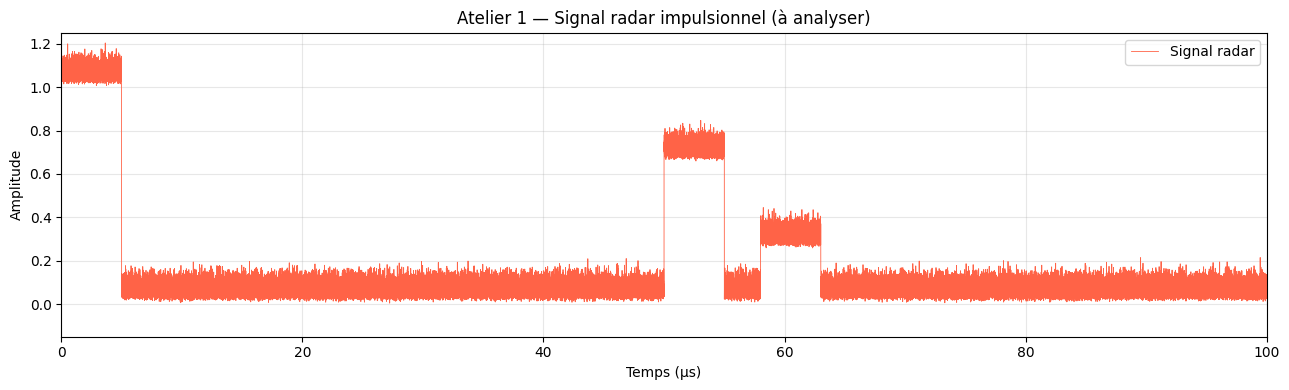

Signal affiché. À vous de jouer : identifiez τ, PRF et les cibles !


In [5]:
# ── Cellule : génération du signal de l'Atelier 1 ───────────────────────────
# Paramètres "cachés" (ceux que les apprenants doivent retrouver)
tau_A1   = 5e-6        # Largeur d'impulsion : 5 µs  (à retrouver)
PRF_A1   = 10e3        # PRF : 10 kHz              (à retrouver)
PRT_A1   = 1 / PRF_A1 # Période de répétition : 100 µs

# Deux cibles
D1 = 7500   # m  →  Δt1 = 50 µs
D2 = 8700   # m  →  Δt2 = 58 µs

t_max = 100e-6          # On affiche une seule période (100 µs)
t_A1  = np.linspace(0, t_max, 100000)

np.random.seed(42)
bruit = np.random.rayleigh(0.04, size=len(t_A1))

def rect_pulse(t, t0, tau, amp):
    return amp * ((t >= t0) & (t < t0 + tau)).astype(float)

# Signal émis (impulsion principale, amplitude 1)
signal_A1 = rect_pulse(t_A1, 0, tau_A1, 1.0) + bruit

# Écho cible 1  (Δt = 2*D1/c)
dt1 = 2 * D1 / c
signal_A1 += rect_pulse(t_A1, dt1, tau_A1, 0.65) + np.random.rayleigh(0.04, len(t_A1)) * 0.3

# Écho cible 2  (Δt = 2*D2/c)
dt2 = 2 * D2 / c
signal_A1 += rect_pulse(t_A1, dt2, tau_A1, 0.25) + np.random.rayleigh(0.04, len(t_A1)) * 0.15

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t_A1 * 1e6, signal_A1, color='tomato', lw=0.6, label='Signal radar')
ax.set_xlabel("Temps (µs)")
ax.set_ylabel("Amplitude")
ax.set_title("Atelier 1 — Signal radar impulsionnel (à analyser)")
ax.set_xlim(0, 100)
ax.set_ylim(-0.15, 1.25)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
#plt.savefig("atelier1_signal.png", dpi=120)
plt.show()
print("Signal affiché. À vous de jouer : identifiez τ, PRF et les cibles !")

## Démarche

### Étape 1 — Lecture de la largeur d'impulsion $\tau$

On lit graphiquement la durée de l'impulsion principale (pic à gauche, amplitude ≈ 1). Sur le graphe, l'axe est gradué en µs.

$$\tau = 5\ \mu s$$

### Étape 2 — Résolution en distance

$$\delta_r = \frac{c \cdot \tau}{2}$$

### Étape 3 — Lecture de la PRF

La **période de répétition** $T$ correspond à l'intervalle entre deux impulsions émises successives. Ici, une seule période est affichée (100 µs), donc $T = 100\ \mu s$ et $PRF = 1/T$.

### Étape 4 — Portée non ambiguë

$$R_{\max} = \frac{c \cdot (T - \tau)}{2}$$

### Étape 5 — Localisation des cibles

Pour chaque écho visible, on mesure le retard $\Delta t$ par rapport à l'impulsion émise, puis :

$$D = \frac{c \cdot \Delta t}{2}$$

In [6]:
# ── Cellule : CORRECTION Atelier 1 ──────────────────────────────────────────

print("=" * 55)
print("   CORRECTION — Atelier 1")
print("=" * 55)

# --- Étape 1 & 2 : largeur d'impulsion et résolution --------
tau_corr = 5e-6          # 5 µs lus sur le graphe
delta_r  = c * tau_corr / 2

print(f"\n① Largeur d'impulsion mesurée : τ = {tau_corr*1e6:.0f} µs")
print(f"   Résolution en distance      : δr = c·τ/2 = {delta_r:.0f} m")

# --- Étape 3 & 4 : PRF et portée non ambiguë ----------------
PRF_corr = 10e3          # 10 kHz → T = 100 µs
PRT_corr = 1 / PRF_corr
R_max    = c * (PRT_corr - tau_corr) / 2

print(f"\n② PRF mesurée : {PRF_corr/1e3:.0f} kHz  →  T = {PRT_corr*1e6:.0f} µs")
print(f"   Portée non ambiguë : Rmax = c·(T-τ)/2 = {R_max/1e3:.1f} km")

# --- Étape 5 : localisation des cibles ----------------------
retards = [50e-6, 58e-6]   # Δt lus sur le graphe (µs)
print(f"\n③ Nombre de cibles détectées : {len(retards)}")
for i, dt in enumerate(retards, 1):
    D = c * dt / 2
    print(f"   Cible {i} :  Δt = {dt*1e6:.0f} µs  →  D = {D/1e3:.1f} km")

# --- Vérification : les cibles sont-elles dans la portée ? --
print(f"\n  Vérification : Rmax = {R_max/1e3:.1f} km")
for i, dt in enumerate(retards, 1):
    D = c * dt / 2
    status = " dans la portée" if D < R_max else "ambiguïté !"
    print(f"   Cible {i} : {D/1e3:.1f} km  →  {status}")

   CORRECTION — Atelier 1

① Largeur d'impulsion mesurée : τ = 5 µs
   Résolution en distance      : δr = c·τ/2 = 750 m

② PRF mesurée : 10 kHz  →  T = 100 µs
   Portée non ambiguë : Rmax = c·(T-τ)/2 = 14.2 km

③ Nombre de cibles détectées : 2
   Cible 1 :  Δt = 50 µs  →  D = 7.5 km
   Cible 2 :  Δt = 58 µs  →  D = 8.7 km

  Vérification : Rmax = 14.2 km
   Cible 1 : 7.5 km  →   dans la portée
   Cible 2 : 8.7 km  →   dans la portée


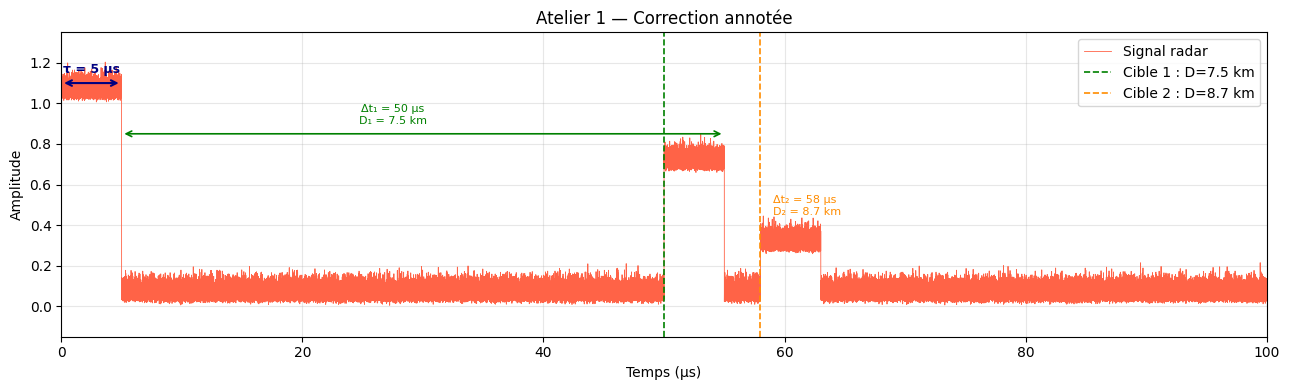

In [7]:
# ── Cellule : visualisation annotée de la correction ────────────────────────
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t_A1 * 1e6, signal_A1, color='tomato', lw=0.6, label='Signal radar')

# Annotation impulsion émise
ax.annotate('', xy=(tau_A1*1e6, 1.1), xytext=(0, 1.1),
            arrowprops=dict(arrowstyle='<->', color='navy', lw=1.5))
ax.text(tau_A1*1e6/2, 1.15, f'τ = {tau_A1*1e6:.0f} µs', ha='center',
        color='navy', fontsize=9, fontweight='bold')

# Annotation cible 1
ax.axvline(dt1*1e6, color='green', lw=1.2, ls='--', label=f'Cible 1 : D={D1/1e3:.1f} km')
ax.annotate('', xy=(dt1*1e6 + tau_A1*1e6, 0.85), xytext=(tau_A1*1e6, 0.85),
            arrowprops=dict(arrowstyle='<->', color='green', lw=1.2))
ax.text((dt1*1e6 + tau_A1*1e6)/2, 0.90,
        f'Δt₁ = {dt1*1e6:.0f} µs\nD₁ = {D1/1e3:.1f} km',
        ha='center', color='green', fontsize=8)

# Annotation cible 2
ax.axvline(dt2*1e6, color='darkorange', lw=1.2, ls='--',
           label=f'Cible 2 : D={D2/1e3:.1f} km')
ax.text(dt2*1e6 + 1, 0.45,
        f'Δt₂ = {dt2*1e6:.0f} µs\nD₂ = {D2/1e3:.1f} km',
        ha='left', color='darkorange', fontsize=8)

ax.set_xlabel("Temps (µs)")
ax.set_ylabel("Amplitude")
ax.set_title("Atelier 1 — Correction annotée")
ax.set_xlim(0, 100)
ax.set_ylim(-0.15, 1.35)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')
plt.tight_layout()
#plt.savefig("atelier1_correction.png", dpi=120)
plt.show()

# Atelier 2 — Radar impulsionnel de poursuite

## Énoncé

Un radar impulsionnel de poursuite présente les caractéristiques suivantes :

| Paramètre | Valeur |
|---|---|
| Fréquence porteuse | $f = 3\ \text{GHz}$ |
| Durée d'impulsion | $\tau = 1\ \mu s$ |
| Fréquence de répétition | $PRF = 400\ \text{Hz}$ |
| Puissance crête | $P_c = 800\ \text{kW}$ |

**Questions :**

1. Déterminer la **puissance moyenne d'émission** $P_{\text{moy}}$.
2. Déterminer la **dimension de la cellule de résolution** $\delta_r$.
3. Déterminer la **distance aveugle** $D_{\text{aveugle}}$.
4. Déterminer la **distance d'ambiguïté** $R_{\max}$.
5. Une cible est à **200 km** : quel retard $\Delta t$ est mesuré par le radar ?
6. Une cible est à **400 km** : quel retard $\Delta t$ est mesuré par le radar ? (attention à l'ambiguïté !)

---

## Démarche de résolution

### Question 1 — Puissance moyenne

La puissance moyenne tient compte du **rapport cyclique** (duty cycle) $DC = \tau \times PRF$ :

$$P_{\text{moy}} = P_c \times DC = P_c \times \tau \times PRF$$

### Question 2 — Cellule de résolution

$$\delta_r = \frac{c \cdot \tau}{2}$$

### Question 3 — Distance aveugle

$$D_{\text{aveugle}} = \frac{c \cdot \tau}{2}$$

> La zone aveugle et la résolution partagent la même formule mais des significations distinctes.

### Question 4 — Distance d'ambiguïté

$$R_{\max} = \frac{c \cdot (PRT - \tau)}{2} \quad \text{avec} \quad PRT = \frac{1}{PRF}$$

### Questions 5 & 6 — Retard mesuré

Le retard réel pour une cible à distance $D$ est $\Delta t_{\text{réel}} = \frac{2D}{c}$.

Mais si $\Delta t_{\text{réel}} > PRT$, le radar **ne peut pas associer l'écho à la bonne impulsion**. Il mesure alors le retard **modulo** la période :

$$\Delta t_{\text{mesuré}} = \Delta t_{\text{réel}} \mod PRT$$

In [10]:
# ── Cellule : CORRECTION Atelier 2 ──────────────────────────────────────────

print("=" * 60)
print("   CORRECTION — Atelier 2 : Radar de poursuite")
print("=" * 60)

# Données du problème
f_A2   = 3e9       # Fréquence porteuse (Hz)
tau_A2 = 1e-6      # Durée d'impulsion (s)
PRF_A2 = 400       # Fréquence de répétition (Hz)
Pc_A2  = 800e3     # Puissance crête (W)

PRT_A2 = 1 / PRF_A2

# ── Q1 : Puissance moyenne ───────────────────────────────────
DC     = tau_A2 * PRF_A2
P_moy  = Pc_A2 * DC

print(f"\n① Puissance moyenne")
print(f"   DC  = τ × PRF = {tau_A2*1e6:.0f} µs × {PRF_A2} Hz = {DC:.2e}")
print(f"   Pmoy = Pc × DC = {Pc_A2/1e3:.0f} kW × {DC:.2e} = {P_moy:.1f} W")

# ── Q2 : Cellule de résolution ───────────────────────────────
delta_r_A2 = c * tau_A2 / 2

print(f"\n② Cellule de résolution")
print(f"   δr = c·τ/2 = {c:.2e} × {tau_A2*1e6:.0f}µs / 2 = {delta_r_A2:.0f} m")

# ── Q3 : Distance aveugle ────────────────────────────────────
D_aveugle_A2 = c * tau_A2 / 2

print(f"\n③ Distance aveugle")
print(f"   D_aveugle = c·τ/2 = {D_aveugle_A2:.0f} m")
print(f"   (identique à δr mais signification différente)")

# ── Q4 : Distance d'ambiguïté ────────────────────────────────
R_max_A2 = c * (PRT_A2 - tau_A2) / 2

print(f"\n④ Distance d'ambiguïté")
print(f"   PRT = 1/PRF = 1/{PRF_A2} Hz = {PRT_A2*1e3:.2f} ms")
print(f"   Rmax = c·(PRT-τ)/2 = {R_max_A2/1e3:.1f} km")

# ── Q5 : Cible à 200 km ──────────────────────────────────────
D_q5 = 200e3   # m
dt_reel_q5    = 2 * D_q5 / c
dt_mesure_q5  = dt_reel_q5 % PRT_A2

print(f"\n⑤ Cible à {D_q5/1e3:.0f} km")
print(f"   Δt_réel    = 2D/c = {dt_reel_q5*1e3:.3f} ms")
print(f"   PRT        = {PRT_A2*1e3:.2f} ms")
if dt_reel_q5 < PRT_A2:
    print(f"   Δt_mesuré  = Δt_réel = {dt_mesure_q5*1e3:.3f} ms →  pas d'ambiguïté")
else:
    print(f"   Δt_mesuré  = Δt_réel mod PRT = {dt_mesure_q5*1e3:.3f} ms")
    n_tours = int(dt_reel_q5 / PRT_A2)
    print(f"   L'écho est reçu après {n_tours} période(s) → ambiguïté !")
    print(f"   Le radar croit voir une cible à D_apparent = {c*dt_mesure_q5/2/1e3:.1f} km")

# ── Q6 : Cible à 400 km ──────────────────────────────────────
D_q6 = 400e3   # m
dt_reel_q6    = 2 * D_q6 / c
dt_mesure_q6  = dt_reel_q6 % PRT_A2

print(f"\n⑥ Cible à {D_q6/1e3:.0f} km")
print(f"   Δt_réel    = 2D/c = {dt_reel_q6*1e3:.3f} ms")
print(f"   PRT        = {PRT_A2*1e3:.2f} ms")
if dt_reel_q6 < PRT_A2:
    print(f"   Δt_mesuré  = Δt_réel = {dt_mesure_q6*1e3:.3f} ms → pas d'ambiguïté")
else:
    print(f"   Δt_mesuré  = Δt_réel mod PRT = {dt_mesure_q6*1e3:.3f} ms")
    n_tours = int(dt_reel_q6 / PRT_A2)
    print(f"   L'écho est reçu après {n_tours} période(s) → AMBIGUÏTÉ !")
    print(f"   Le radar croit voir une cible à D_apparent = {c*dt_mesure_q6/2/1e3:.1f} km")

   CORRECTION — Atelier 2 : Radar de poursuite

① Puissance moyenne
   DC  = τ × PRF = 1 µs × 400 Hz = 4.00e-04
   Pmoy = Pc × DC = 800 kW × 4.00e-04 = 320.0 W

② Cellule de résolution
   δr = c·τ/2 = 3.00e+08 × 1µs / 2 = 150 m

③ Distance aveugle
   D_aveugle = c·τ/2 = 150 m
   (identique à δr mais signification différente)

④ Distance d'ambiguïté
   PRT = 1/PRF = 1/400 Hz = 2.50 ms
   Rmax = c·(PRT-τ)/2 = 374.9 km

⑤ Cible à 200 km
   Δt_réel    = 2D/c = 1.333 ms
   PRT        = 2.50 ms
   Δt_mesuré  = Δt_réel = 1.333 ms →  pas d'ambiguïté

⑥ Cible à 400 km
   Δt_réel    = 2D/c = 2.667 ms
   PRT        = 2.50 ms
   Δt_mesuré  = Δt_réel mod PRT = 0.167 ms
   L'écho est reçu après 1 période(s) → AMBIGUÏTÉ !
   Le radar croit voir une cible à D_apparent = 25.0 km


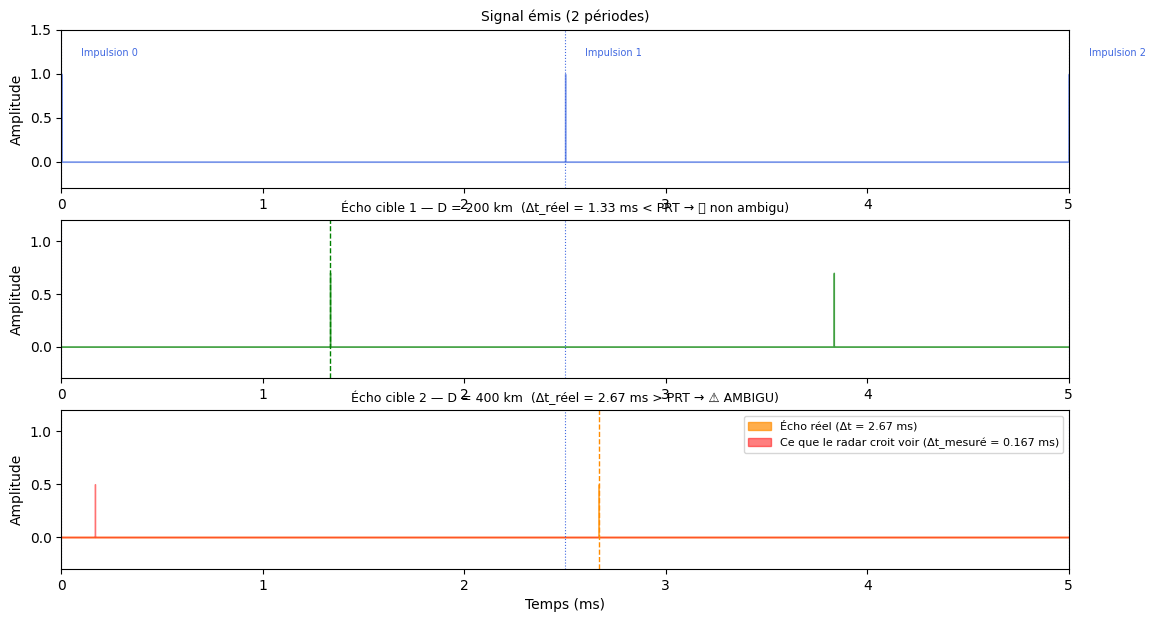

In [12]:
# ── Cellule : schéma temporel illustrant l'ambiguïté ────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=False)

# Palette couleurs
col_tx  = 'royalblue'
col_c1  = 'green'
col_c2  = 'darkorange'

# ── Axe supérieur : signal émis (2 périodes) ─────────────────
t_plot = np.linspace(0, 2 * PRT_A2, 50000)
tx = np.zeros_like(t_plot)
for k in range(3):
    mask = (t_plot >= k * PRT_A2) & (t_plot < k * PRT_A2 + tau_A2)
    tx[mask] = 1.0

axes[0].fill_between(t_plot * 1e3, tx, color=col_tx, alpha=0.7)
axes[0].set_ylabel("Amplitude")
axes[0].set_title("Signal émis (2 périodes)", fontsize=10)
axes[0].set_ylim(-0.3, 1.5)
axes[0].set_xlim(0, 2 * PRT_A2 * 1e3)
for k in range(3):
    axes[0].axvline(k * PRT_A2 * 1e3, color=col_tx, lw=0.8, ls=':')
    axes[0].text(k * PRT_A2 * 1e3 + 0.1, 1.2, f'Impulsion {k}',
                 fontsize=7, color=col_tx)

# ── Axe central : cible à 200 km (pas d'ambiguïté) ──────────
rx_c1 = np.zeros_like(t_plot)
t0_c1 = dt_reel_q5
if t0_c1 < t_plot[-1]:
    mask = (t_plot >= t0_c1) & (t_plot < t0_c1 + tau_A2)
    rx_c1[mask] = 0.7
t0_c1_2 = dt_reel_q5 + PRT_A2
if t0_c1_2 < t_plot[-1]:
    mask = (t_plot >= t0_c1_2) & (t_plot < t0_c1_2 + tau_A2)
    rx_c1[mask] = 0.7

axes[1].fill_between(t_plot * 1e3, rx_c1, color=col_c1, alpha=0.7)
axes[1].axvline(dt_reel_q5 * 1e3, color=col_c1, lw=1, ls='--')
axes[1].set_ylabel("Amplitude")
axes[1].set_title(f"Écho cible 1 — D = {D_q5/1e3:.0f} km  (Δt_réel = {dt_reel_q5*1e3:.2f} ms < PRT → ✅ non ambigu)",
                  fontsize=9)
axes[1].set_ylim(-0.3, 1.2)
axes[1].set_xlim(0, 2 * PRT_A2 * 1e3)
for k in range(3):
    axes[1].axvline(k * PRT_A2 * 1e3, color=col_tx, lw=0.8, ls=':')

# ── Axe inférieur : cible à 400 km (ambiguïté) ───────────────
rx_c2 = np.zeros_like(t_plot)
t0_c2 = dt_reel_q6
if t0_c2 < t_plot[-1]:
    mask = (t_plot >= t0_c2) & (t_plot < t0_c2 + tau_A2)
    rx_c2[mask] = 0.5

axes[2].fill_between(t_plot * 1e3, rx_c2, color=col_c2, alpha=0.7,
                     label=f'Écho réel (Δt = {dt_reel_q6*1e3:.2f} ms)')

# Ce que le radar "voit" (écho associé à l'impulsion 1, pas l'impulsion 0)
rx_c2_vu = np.zeros_like(t_plot)
t0_vu = dt_mesure_q6
mask  = (t_plot >= t0_vu) & (t_plot < t0_vu + tau_A2)
rx_c2_vu[mask] = 0.5
axes[2].fill_between(t_plot * 1e3, rx_c2_vu, color='red', alpha=0.5,
                     label=f'Ce que le radar croit voir (Δt_mesuré = {dt_mesure_q6*1e3:.3f} ms)')

axes[2].axvline(dt_reel_q6 * 1e3, color=col_c2, lw=1, ls='--')
axes[2].set_ylabel("Amplitude")
axes[2].set_xlabel("Temps (ms)")
axes[2].set_title(f"Écho cible 2 — D = {D_q6/1e3:.0f} km  (Δt_réel = {dt_reel_q6*1e3:.2f} ms > PRT → ⚠️ AMBIGU)",
                  fontsize=9)
axes[2].set_ylim(-0.3, 1.2)
axes[2].set_xlim(0, 2 * PRT_A2 * 1e3)
for k in range(3):
    axes[2].axvline(k * PRT_A2 * 1e3, color=col_tx, lw=0.8, ls=':')
axes[2].legend(fontsize=8)

#plt.tight_layout()
#lt.savefig("atelier2_ambiguite.png", dpi=120)
plt.show()

In [14]:
# ── Cellule : bilan récapitulatif Atelier 2 ─────────────────────────────────

print("=" * 60)
print("   BILAN — Atelier 2")
print("=" * 60)
print(f"""
  Paramètres du radar
  ───────────────────
  Fréquence porteuse   f   = {f_A2/1e9:.0f} GHz
  Durée d'impulsion    τ   = {tau_A2*1e6:.0f} µs
  PRF                      = {PRF_A2} Hz
  PRT                      = {PRT_A2*1e3:.2f} ms
  Puissance crête      Pc  = {Pc_A2/1e3:.0f} kW

  Résultats
  ─────────
  Rapport cyclique     DC          = {DC:.2e}  ({DC*100:.4f} %)
  Puissance moyenne    Pmoy        = {P_moy:.1f} W
  Résolution distance  δr          = {delta_r_A2:.0f} m
  Distance aveugle     D_aveugle   = {D_aveugle_A2:.0f} m
  Portée non ambiguë   Rmax        = {R_max_A2/1e3:.1f} km

  Cible à 200 km → Δt mesuré = {dt_mesure_q5*1e3:.3f} ms  (réel = {dt_reel_q5*1e3:.3f} ms)
  Cible à 400 km → Δt mesuré = {dt_mesure_q6*1e3:.3f} ms  ⚠️  (réel = {dt_reel_q6*1e3:.3f} ms)
                   D apparente = {c*dt_mesure_q6/2/1e3:.1f} km  ← ERREUR par ambiguïté !
""")

   BILAN — Atelier 2

  Paramètres du radar
  ───────────────────
  Fréquence porteuse   f   = 3 GHz
  Durée d'impulsion    τ   = 1 µs
  PRF                      = 400 Hz
  PRT                      = 2.50 ms
  Puissance crête      Pc  = 800 kW

  Résultats
  ─────────
  Rapport cyclique     DC          = 4.00e-04  (0.0400 %)
  Puissance moyenne    Pmoy        = 320.0 W
  Résolution distance  δr          = 150 m
  Distance aveugle     D_aveugle   = 150 m
  Portée non ambiguë   Rmax        = 374.9 km

  Cible à 200 km → Δt mesuré = 1.333 ms  (réel = 1.333 ms)
  Cible à 400 km → Δt mesuré = 0.167 ms  ⚠️  (réel = 2.667 ms)
                   D apparente = 25.0 km  ← ERREUR par ambiguïté !



## Synthèse — Compromis du design radar

Les ateliers 1 et 2 mettent en évidence les **compromis fondamentaux** du radar impulsionnel :

| Paramètre | ↑ Augmenter | ↓ Diminuer |
|---|---|---|
| $\tau$ (durée impulsion) | + énergie par impulsion | − résolution, - zone aveugle |
| $PRF$ | + puissance moyenne | − portée non ambiguë |
| $P_c$ (puissance crête) | + portée | + complexité / coût |